# ARIMA — Checkpoint (week 4)

Maak per dataset een ARIMA-analyse met grid search naar optimale (p,d,q)-parameters.

## BELANGRIJK: gebruik exact de genoemde variabelennamen
De checks (`checks/test_week04.py`) voeren dit notebook uit en controleren volgende
variabelen. Gebruik exact deze namen, anders falen de checks:

- Oefening 1 (TF_BIRTHS): `series_births`, `births_2022_daily`, `monthly_births`,
  `best_order_births`, `rmse_births`
- Oefening 2 (AQI Duitsland): `aqi_germany`, `aqi_filtered`, `best_order_aqi`, `rmse_aqi`
- Oefening 3 (Electric Production): `series_electric`, `best_order_electric`, `rmse_electric`
- Meerkeuze: `antwoord_adf`, `antwoord_seizoen_births` (waarde "A", "B", "C" of "D")

Conventies die de checks gebruiken: alle grid searches met `p_values = [0, 1, 2, 4]`,
`d_values = [0, 1]`, `q_values = [0, 1]` en een 66/34 train/test-split
(`train_size = int(len(X) * 0.66)`) zoals in de gegeven helperfuncties.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from math import sqrt
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

def evaluate_arima_model(X, arima_order):
    """Walk-forward validatie: RMSE van een ARIMA(order) op reeks X (66/34-split)."""
    X = np.asarray(X, dtype="float32").ravel()
    train_size = int(len(X) * 0.66)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=arima_order)
        model_fit = model.fit()
        predictions.append(model_fit.forecast()[0])
        history.append(test[t])
    return sqrt(mean_squared_error(test, predictions))

def grid_search_arima(X, p_values, d_values, q_values):
    """Zoekt beste (p,d,q) via walk-forward RMSE. Geeft (best_order, best_rmse)."""
    best_score, best_cfg = float("inf"), None
    for p in p_values:
        for d in d_values:
            for q in q_values:
                try:
                    rmse = evaluate_arima_model(X, (p, d, q))
                except Exception:
                    continue
                if rmse < best_score:
                    best_score, best_cfg = rmse, (p, d, q)
    return best_cfg, best_score

p_values = [0, 1, 2, 4]
d_values = [0, 1]
q_values = [0, 1]


## Oefening 1 — TF_BIRTHS (geboortecijfers België)

1. Laad `./data/TF_BIRTHS.csv` in (scheidingsteken `;`) en hernoem de kolom
   `MS_NUM_BIRTHS` naar `value`. Parse de eerste kolom (`DT_DATE`, formaat
   `%d/%m/%Y`) als index. Sla op in **`series_births`** (DataFrame).
2. Maak **`births_2022_daily`**: enkel de dagcijfers van 2022. Maak een plot en
   bekijk het histogram van de dagcijfers — wat valt op? Hoe komt dat ?
3. Maak **`monthly_births`**: de volledige reeks hersamplet naar maanden (som).
   Welk seizoenspatroon zie je? (beantwoord de meerkeuzevraag verderop)
4. Test met de ADF-test of de maandreeks stationair is.
5. Zoek met grid search de beste ARIMA-parameters voor de maandreeks en sla op in
   **`best_order_births`** (tuple) en de bijhorende walk-forward RMSE in
   **`rmse_births`**.
6. Fit het finale model en plot de residuals.


AAAAAAAAAAAAAAAAAAAAAAAA        value series_births
10958    206    2022-01-01
10959    185    2022-01-02
10960    360    2022-01-03
10961    348    2022-01-04
10962    350    2022-01-05
10963    361    2022-01-06
10964    355    2022-01-07
10965    217    2022-01-08
10966    222    2022-01-09
10967    351    2022-01-10
10968    376    2022-01-11
10969    367    2022-01-12
10970    331    2022-01-13
10971    377    2022-01-14


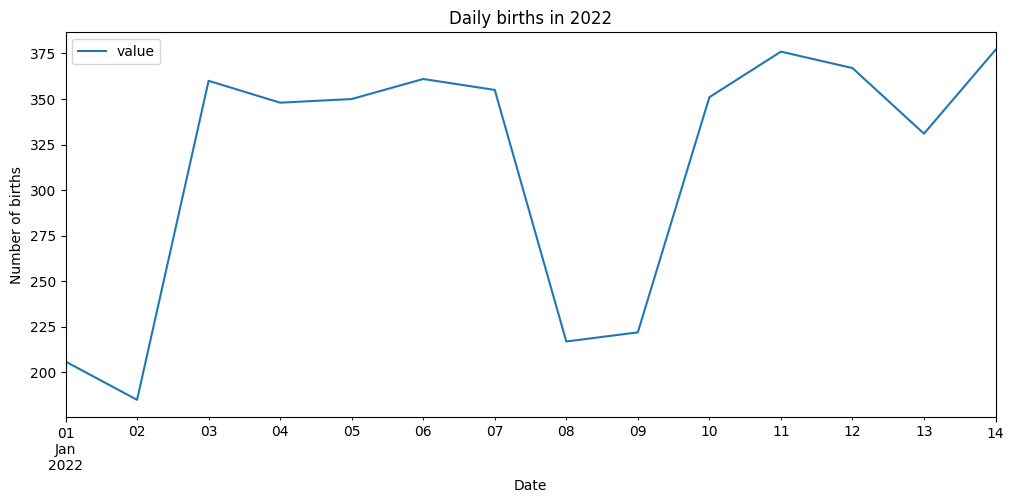

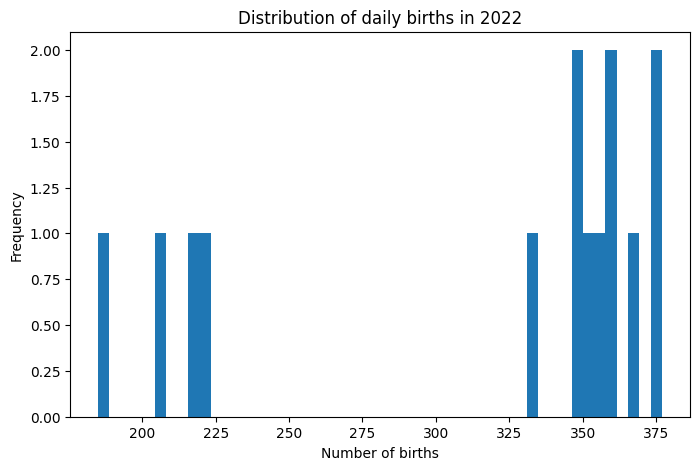

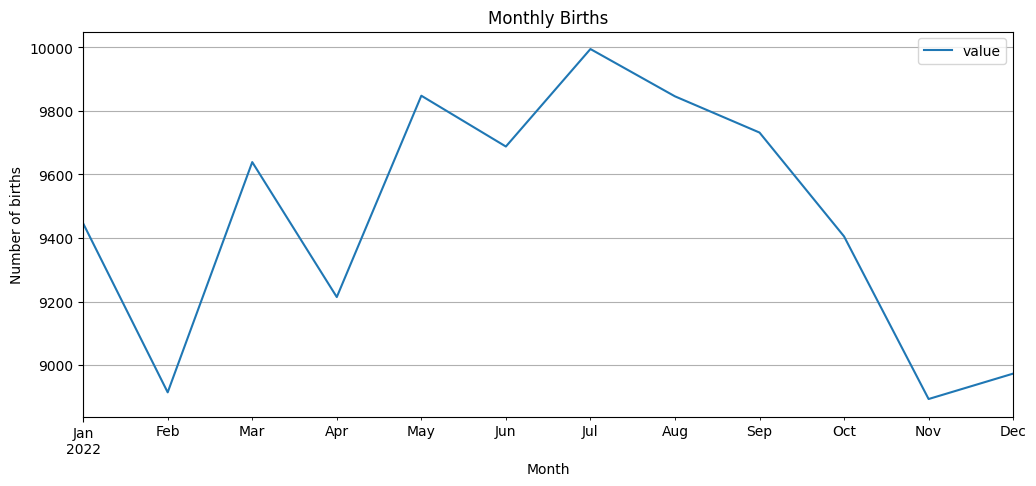

ADF statistiek: -11.686044
p-waarde: 0.000000
best stat order: ((4, 0, 0), 249.12461584265412)
kidneren geboren in januari: 9446
kidneren geboren in december: 8973
                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                11323
Model:                 ARIMA(4, 1, 1)   Log Likelihood              -61769.244
Date:                Mon, 12 Oct 2026   AIC                         123550.489
Time:                        10:52:07   BIC                         123594.496
Sample:                             0   HQIC                        123565.293
                              - 11323                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3924      0.009     42.982   

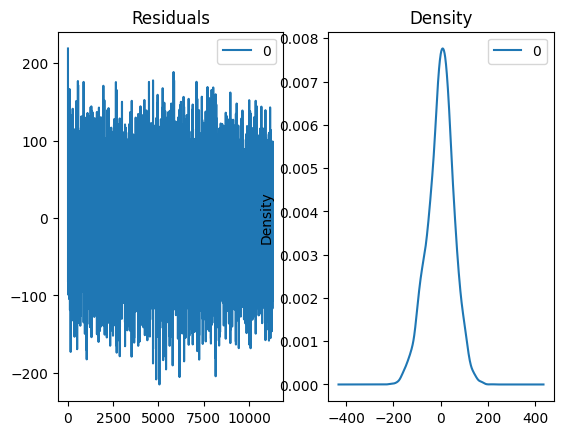

In [ ]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)
df = pd.read_csv('./data/TF_BIRTHS.csv', sep=";")
# print(birth_data["MS_NUM_BIRTHS"])

df["value"] = df["MS_NUM_BIRTHS"]
df["series_births"] = pd.to_datetime(df["DT_DATE"], format="%d/%m/%Y")

df = df.drop(columns=["MS_NUM_BIRTHS","DT_DATE"])
df.set_index("series_births")

# 2
births_2022_daily = df[df["series_births"] >= pd.Timestamp("2022-01-01")]
births_2022_2weeks = df[(df["series_births"] >= pd.Timestamp("2022-01-01")) & (df["series_births"] <= pd.Timestamp("2022-01-14"))]
print(f"AAAAAAAAAAAAAAAAAAAAAAAA {births_2022_2weeks}")
# ---------
# Graph of daily births in 2022
births_2022_daily.plot(
    x="series_births",
    y="value",
    title="Daily births in 2022",
    figsize=(12, 5)
)

plt.xlabel("Date")
plt.ylabel("Number of births")
plt.show()


# Histogram of daily births in 2022
births_2022_daily["value"].plot(
    kind="hist",
    bins=50,
    title="Distribution of daily births in 2022",
    figsize=(8, 5)
)

plt.xlabel("Number of births")
plt.ylabel("Frequency")
plt.show()

# -------

# 3
#ME = MONTH END, on = waar gaan we op resamplen?
monthly_births = births_2022_daily.resample("ME", on="series_births").sum()

# -------
monthly_births.plot(
    kind="line",
    figsize=(12, 5),
    title="Monthly Births"
)

plt.xlabel("Month")
plt.ylabel("Number of births")
plt.grid()
plt.show()
# -------
# 4
result = adfuller(monthly_births)
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1]) # als p groter is dan 0.05, dan mag je ervan uitgaan dat de reeks niet-stationair is

arima_grid = grid_search_arima(monthly_births, p_values, d_values, q_values)
print(f"best stat order: {arima_grid}")

best_order_births = arima_grid[0]
rmse_births = arima_grid[1]

print(f"kidneren geboren in januari: {monthly_births["value"][0]}")
print(f"kidneren geboren in december: {monthly_births["value"][11]}")


# 5
model = ARIMA(df.value, order=(4,1,1))
model_fit = model.fit()
print(model_fit.summary())

# 6
residuals = pd.DataFrame(model_fit.resid)
fig, ax = plt.subplots(1,2)
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Density', ax=ax[1])
plt.show()

## Oefening 2 — AQI: luchtkwaliteit Duitsland

1. Laad `./data/data_date.csv` in (eerste kolom = datum-index).
2. Filter op `Country == 'Germany'` en hou enkel de kolom `AQI Value` (hernoemd naar
   `value`). Sla op in **`aqi_germany`**.
3. Filter de data tussen 21 juli 2022 en 22 september 2022 → **`aqi_filtered`**.
4. Test met de ADF-test of de reeks stationair is (beantwoord daarna de
   meerkeuzevraag `antwoord_adf`).
5. Grid search → **`best_order_aqi`** en **`rmse_aqi`**. Fit het finale model en
   plot de residuals.


               Country                          Status  AQI Value
Date                                                             
2022-07-21     Albania                            Good         14
2022-07-21     Algeria                        Moderate         65
2022-07-21     Andorra                        Moderate         55
2022-07-21      Angola  Unhealthy for Sensitive Groups        113
2022-07-21   Argentina                        Moderate         63
...                ...                             ...        ...
2023-08-10  Uzbekistan                            Good         28
2023-08-10     Vatican                            Good         34
2023-08-10   Venezuela                            Good         26
2023-08-10     Vietnam  Unhealthy for Sensitive Groups        142
2023-08-10      Zambia                        Moderate         79

[12986 rows x 3 columns]
datetime64[ns]
            value
Date             
2022-07-21     77
2022-07-21     79
2022-07-22     58
2022-07-22 

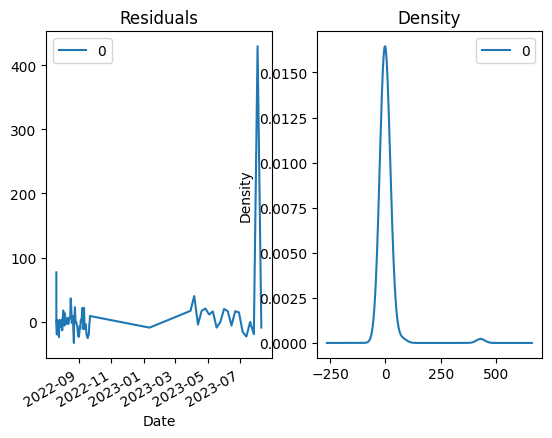

In [195]:
# # TODO: vul hier je oplossing in (zie opdracht hierboven)
# # 1
# df = pd.read_csv('./data/data_date.csv', sep=",", header=0,index_col=0)
# print(df)
# #stupid fucking line btw why is this necessary if its OBVIOUSLY A DATETIME OBJECT
# df['Date'] = pd.to_datetime(df['Date'])

# # 2
# aqi_germany = df[df["Country"] == "Germany"]
# aqi_germany["value"] = aqi_germany["AQI Value"]
# aqi_germany = aqi_germany.drop(columns=["AQI Value", "Status", "Date", "Country"])

# # 3
# aqi_filtered = df[(df['Date'] > pd.Timestamp('2022-07-21')) & (df['Date'] < pd.Timestamp('2022-09-22'))]

# # 4
# print(df["Date"].dtype)
# result = adfuller(aqi_germany["value"])
# print('ADF statistiek: %f' % result[0])
# print('p-waarde: %f' % result[1]) # als p groter is dan 0.05, dan mag je ervan uitgaan dat de reeks niet-stationair is

# # arima_grid_result = grid_search_arima(aqi_germany["value"], p_values, d_values, q_values)
# # best_order_aqi = arima_grid_result[0]
# # rmse_aqi = arima_grid_result[1]

# # print(f"best stat order: {arima_grid}")

# # print(f"best stats: {best_order_aqi}")
# # print(f"best RMSE: {rmse_aqi}")

# # 5
# model = ARIMA(aqi_germany.value, order=(4,1,1))
# model_fit = model.fit()
# print(model_fit.summary())

# residuals = pd.DataFrame(model_fit.resid)
# fig, ax = plt.subplots(1,2)
# residuals.plot(title="Residuals", ax=ax[0])
# residuals.plot(kind='kde', title='Density', ax=ax[1])
# plt.show()

# TODO: vul hier je oplossing in (zie opdracht hierboven)

# 1
df = pd.read_csv(
    './data/data_date.csv',
    sep=",",
    header=0,
    index_col=0,
    parse_dates=True
)

print(df)
print(df.index.dtype)


# 2
aqi_germany = df[df["Country"] == "Germany"].copy()

aqi_germany["value"] = aqi_germany["AQI Value"]

aqi_germany = aqi_germany.drop(
    columns=["AQI Value", "Status", "Country"]
)

print(aqi_germany)


# 3
aqi_filtered = df[
    (df.index > pd.Timestamp('2022-07-21')) &
    (df.index < pd.Timestamp('2022-09-22'))
]

print(aqi_filtered)


# 4
result = adfuller(aqi_germany["value"])

print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])
# als p groter is dan 0.05, dan mag je ervan uitgaan
# dat de reeks niet-stationair is


# 5
model = ARIMA(
    aqi_germany["value"],
    order=(4, 1, 1)
)

model_fit = model.fit()

print(model_fit.summary())


# 6
residuals = pd.DataFrame(model_fit.resid)

fig, ax = plt.subplots(1, 2)

residuals.plot(
    title="Residuals",
    ax=ax[0]
)

residuals.plot(
    kind='kde',
    title='Density',
    ax=ax[1]
)

plt.show()

## Oefening 3 — Electric Production

1. Laad `./data/Electric_Production.xls` in (het is effectief een CSV; eerste kolom =
   datum-index) en hernoem `Value` naar `value` → **`series_electric`**.
2. Bekijk de reeks: hier is duidelijk een trend én een seizoenspatroon, dus `d = 1`
   is een goede keuze voor de differencing.
3. Grid search → **`best_order_electric`** en **`rmse_electric`**. Fit het finale
   model en plot walk-forward voorspellingen tegen de testset.


           DATE  series_electric
0    01-01-1985          72.5052
1    02-01-1985          70.6720
2    03-01-1985          62.4502
3    04-01-1985          57.4714
4    05-01-1985          55.3151
..          ...              ...
392  09-01-2017          98.6154
393  10-01-2017          93.6137
394  11-01-2017          97.3359
395  12-01-2017         114.7212
396  01-01-2018         129.4048

[397 rows x 2 columns]


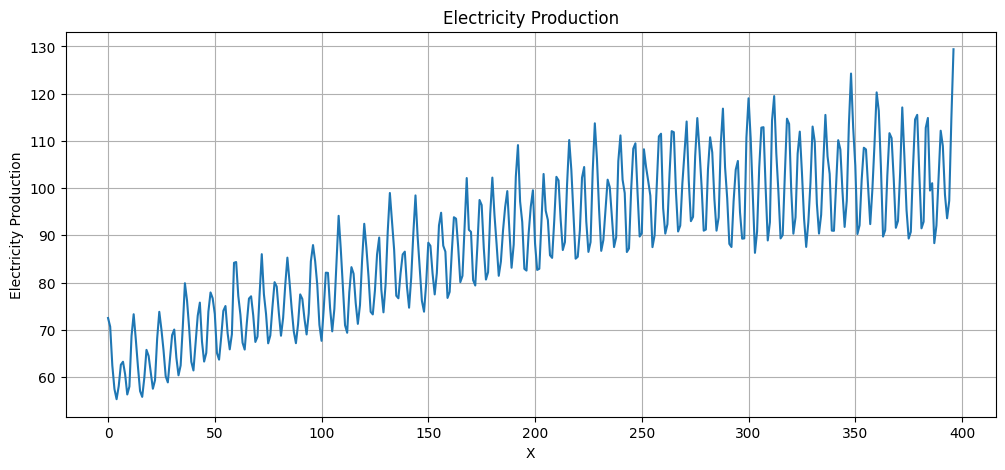

                               SARIMAX Results                                
Dep. Variable:        series_electric   No. Observations:                  397
Model:                 ARIMA(4, 1, 1)   Log Likelihood               -1101.271
Date:                Mon, 12 Oct 2026   AIC                           2214.542
Time:                        10:46:48   BIC                           2238.431
Sample:                             0   HQIC                          2224.006
                                - 397                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0641      0.108      0.593      0.553      -0.148       0.276
ar.L2         -0.4678      0.047    -10.028      0.000      -0.559      -0.376
ar.L3         -0.4552      0.046     -9.981      0.0

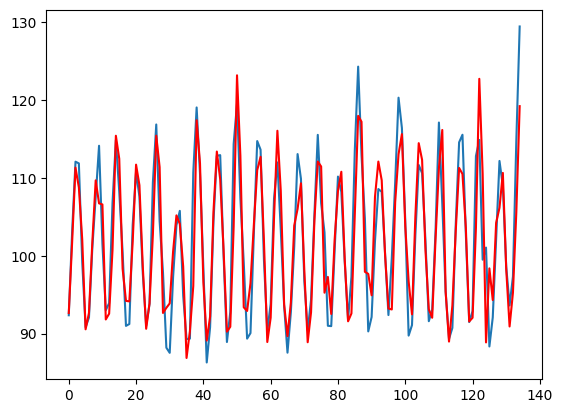

In [ ]:
# TODO: vul hier je oplossing in (zie opdracht hierboven)

df = pd.read_csv("./data/Electric_Production.xls")

df["series_electric"] = df["Value"]
df = df.drop(columns="Value")
print(df)

df["series_electric"].plot(
    kind="line",
    figsize=(12, 5),
    title="Electricity Production"
)

plt.xlabel("X")
plt.ylabel("Electricity Production")
plt.grid()
plt.show()

# 2
# result = grid_search_arima(df["series_electric"], p_values, d_values, q_values)

# print(result[0])
# print(result[1])

# 3
model = ARIMA(df["series_electric"], order=(4,1,1))
model_fit = model.fit()
print(model_fit.summary())


X = df["series_electric"].values # df is al 1 enkele kolom.
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()

for t in range(len(test)):
    model = ARIMA(history, order=(4,1,1))
    model_fit = model.fit()

    output = model_fit.forecast()
    yhat = np.asarray(output).ravel()[0]

    predictions.append(yhat)

    obs = test[t]
    history.append(obs)

    print('predicted=%f, expected=%f' % (yhat, obs))

rmse = sqrt(mean_squared_error(test, predictions))
print('Test RMSE: %.3f' % rmse)

plt.plot(test)
plt.plot(predictions, color='red')
plt.show()

## Meerkeuzevragen

**Vraag 1 (ADF):** de p-waarde van de ADF-test op de gefilterde AQI-reeks van Duitsland
is kleiner dan 0.05. Wat betekent dit?

- A) De reeks is niet-stationair; er is differencing nodig
- B) De reeks is stationair; differencing is niet nodig
- C) De reeks heeft een sterke trend
- D) De ADF-test zegt niets over stationariteit

**Vraag 2 (seizoen geboortes):** welk seizoenspatroon zie je in de maandelijkse
geboortecijfers van België?

- A) Geen enkel seizoenspatroon
- B) Een piek rond juli-september
- C) Enkel een piek in december
- D) Een lineair dalende trend zonder seizoenen


In [ ]:
# Vraag 1: vul "A", "B", "C" of "D" in
antwoord_adf = "B"

In [ ]:
# Vraag 2: vul "A", "B", "C" of "D" in
antwoord_seizoen_births = "B"